
# EMNIST Balanced — Exploratory Data Analysis

## Objective
Explore the EMNIST Balanced dataset and prepare it for handwritten character classification.

## Dataset overview
- **Dataset:** EMNIST Balanced
- **Task:** Handwritten character classification
- **Image dimensions:** 28 × 28 pixels
- **Image type:** Grayscale
- **Number of classes:** 47

## Analysis goals
1. Load the dataset from local IDX files.
2. Examine the dataset structure and data types.
3. Analyze class distribution.
4. Visualize sample characters and inspect image orientation.
5. Identify preprocessing requirements before model development.


In [18]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.handwritten_recognition.data import (
    CLASS_MAPPING,
    TEST_IMAGES,
    TEST_LABELS,
    TRAIN_IMAGES,
    TRAIN_LABELS,
    load_idx_images,
    load_idx_labels,
)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)


## 1. Load the Dataset

The EMNIST files are stored in compressed IDX format. The project's data-loading functions parse the image and label files into NumPy arrays.

We load the training and test splits separately and keep the test split reserved for final model evaluation.


In [19]:
X_train = load_idx_images(TRAIN_IMAGES)
y_train = load_idx_labels(TRAIN_LABELS)

X_test = load_idx_images(TEST_IMAGES)
y_test = load_idx_labels(TEST_LABELS)


## 2. Data Validation

Before analyzing the dataset, we check the dimensions, data types, pixel intensity range, and label values. These checks help detect malformed data and confirm that images correspond to their labels.


In [20]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

print("\nImage dtype:", X_train.dtype)
print("Label dtype:", y_train.dtype)
print("Pixel intensity range:", X_train.min(), "to", X_train.max())

print("\nNumber of classes:", len(np.unique(y_train)))
print("Training label range:", y_train.min(), "to", y_train.max())

assert X_train.shape == (112800, 28, 28)
assert X_test.shape == (18800, 28, 28)
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert X_train.dtype == np.uint8
assert y_train.dtype == np.uint8
assert set(np.unique(y_train)) == set(range(47))
assert set(np.unique(y_test)) == set(range(47))

print("\nAll dataset validation checks passed.")

Training images: (112800, 28, 28)
Training labels: (112800,)
Test images: (18800, 28, 28)
Test labels: (18800,)

Image dtype: uint8
Label dtype: uint8
Pixel intensity range: 0 to 255

Number of classes: 47
Training label range: 0 to 46

All dataset validation checks passed.



## 3. Class Mapping

Each integer label represents a character class. The mapping file associates label IDs with Unicode character codes, allowing us to display readable character labels during analysis.


In [21]:
mapping_data = np.loadtxt(CLASS_MAPPING, dtype=np.int64)

class_to_char = {
    int(label): chr(int(codepoint))
    for label, codepoint in mapping_data
}

print("Number of mapped classes:", len(class_to_char))
print("Sample mappings:")

for label in sorted(class_to_char)[:15]:
    print(f"{label}: {class_to_char[label]}")

Number of mapped classes: 47
Sample mappings:
0: 0
1: 1
2: 2
3: 3
4: 4
5: 5
6: 6
7: 7
8: 8
9: 9
10: A
11: B
12: C
13: D
14: E



## 4. Class Distribution

Examine the number of samples assigned to each class in the training and test splits. This helps verify that the dataset's class balance is consistent with its intended design.


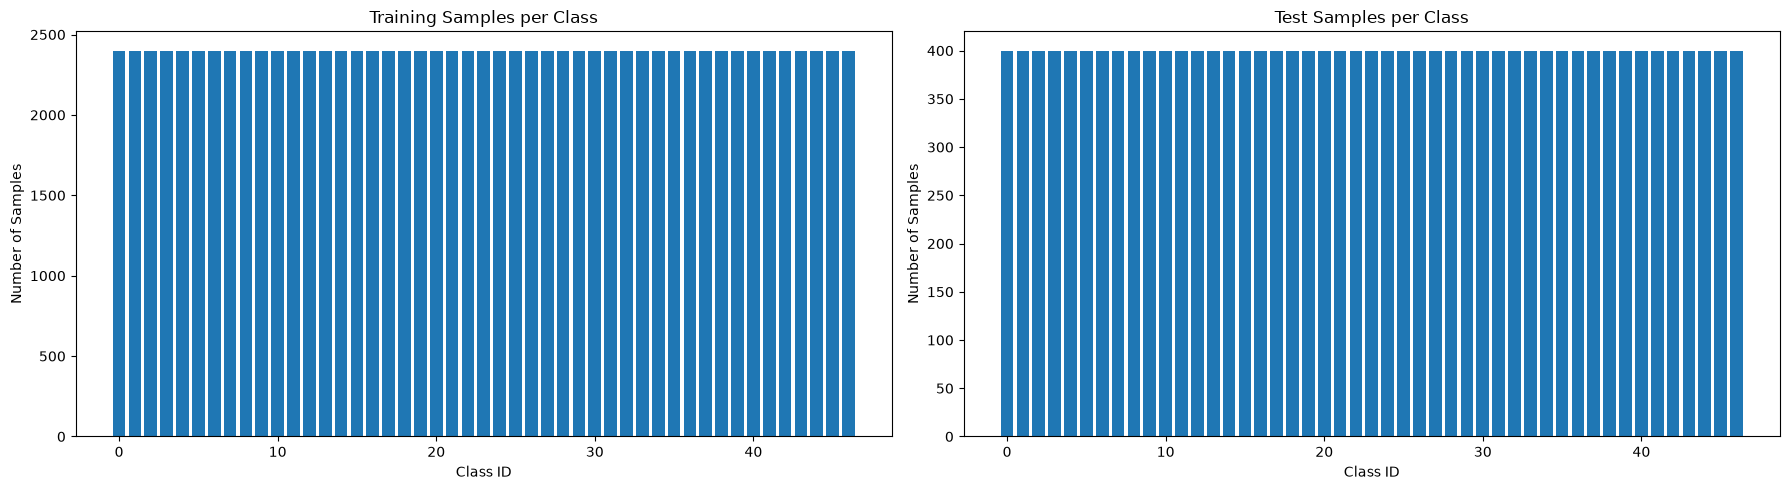

Training count range: 2400 to 2400
Test count range: 400 to 400


In [22]:
train_counts = np.bincount(y_train, minlength=47)
test_counts = np.bincount(y_test, minlength=47)

class_labels = [
    f"{label}: {class_to_char[label]}"
    for label in range(47)
]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].bar(range(47), train_counts)
axes[0].set_title("Training Samples per Class")
axes[0].set_xlabel("Class ID")
axes[0].set_ylabel("Number of Samples")

axes[1].bar(range(47), test_counts)
axes[1].set_title("Test Samples per Class")
axes[1].set_xlabel("Class ID")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

print("Training count range:", train_counts.min(), "to", train_counts.max())
print("Test count range:", test_counts.min(), "to", test_counts.max())


## 5. Visualize Character Samples

Visualize a random selection of training images with their decoded character labels. EMNIST images can appear transposed when read directly from the IDX files, so the display uses a transpose to inspect the characters in their intended orientation.


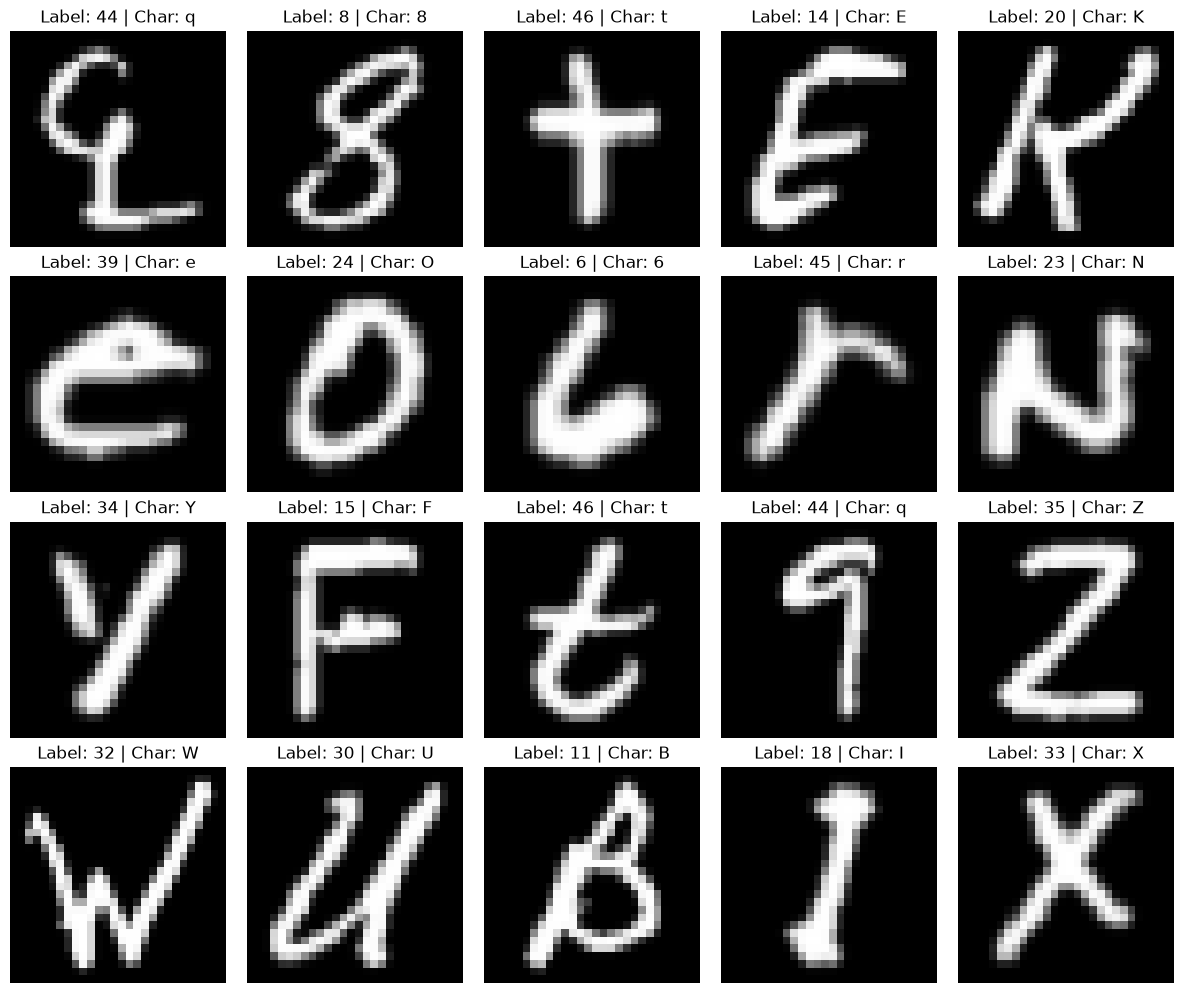

In [24]:
sample_indices = rng.choice(len(X_train), size=20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, idx in zip(axes.flat, sample_indices):
    image = X_train[idx].T
    label = int(y_train[idx])
    character = class_to_char[label]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label} | Char: {character}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Findings and Preprocessing Decisions

### Dataset validation
- Training split: 112,800 images.
- Test split: 18,800 images.
- Image dimensions: 28 × 28 pixels.
- Number of classes: 47.

### Observations
- Class distribution: [Record the observed training and test counts.]
- Image orientation: [Record whether the displayed characters are upright.]
- Image quality: [Record any unusual samples or visible issues.]

### Preprocessing decisions
- Convert pixel values from the 0–255 range to the 0–1 range for model input.
- Apply the required image orientation correction consistently.
- Convert images and labels to PyTorch-compatible tensors in the data pipeline.
- Keep the official test split separate from training and model-selection decisions.

### Conclusion
The dataset has been loaded and explored. The next phase will establish a baseline classifier and define a reproducible experimental setup.



## Phase 1 Summary

The EMNIST Balanced dataset has been loaded from local compressed IDX files. Its structure, labels, class distribution, and sample images have been examined.

The exploration establishes the data-loading foundation for the next phase: baseline modeling and experimental design.

**Status:** Complete after all validation checks pass and the visual inspection and findings have been recorded.
